# Few-shot runs for the presentation

Three questions, from every few-shot run in `lightning_logs/`:

1. Does the number of labelled training tiles per species change the score?
2. Does the number of background-only tiles change the score?
3. Does the training crop size change the score, including at the same tile counts?

Run this notebook from the repo root. It only reads `lightning_logs/` and writes PNGs to `notebooks/few_shot_figures/`.

**What each run is.** U-Net, MiT-B2, fold 3, seed 42. The directory name `train_512` or `train_1024` is the crop window. `t10` is 10 labelled tiles per species (`few_shot_k`). `tbg1000` is 1000 extra background-only tiles (`few_shot_bg_k`). The usual way those tiles are chosen is `max_px_site_pheno`. A cross, and a `*` in the heatmap, means the run used another selection mode. Those points are drawn, but they are not connected.

**Crop size is context, not a resample.** A 512 px crop is a smaller window of the same imagery as a 1024 px crop. A plant stays about the same size in pixels. The window covers about 2.4 m on a side instead of 4.8 m.

**Which test these scores are.** Each point is the latest `test_*/quantitative` result in that run. The test folders are named `np_debug`: these run names do not match the `np_cv*` pattern `test.py` uses to pick a fold's held-out sites, so evaluation used the Sion debug split. On that split only *R. typhina* and *B. davidii* have labels. The summary score is mean species F1 (`F1-avg-wo0`): the average F1 of species that have labels, with background left out. The following panels show each species on its own. A species with no labelled pixels on this test is blank, and it is not part of the average.

One 1024 run (23 Oct, 10 tiles per species, 1000 background tiles) has no test output. It is listed and then left out of the figures. `k = 50` was only trained with 10 background tiles, so it is on the heatmap and the matched-crop figure, not on the curve that holds background at 1000.


In [8]:
from pathlib import Path
import json
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FixedLocator, FuncFormatter, NullFormatter

cwd = Path.cwd()
if (cwd / "lightning_logs").is_dir():
    repo = cwd
elif (cwd.parent / "lightning_logs").is_dir():
    repo = cwd.parent
else:
    raise FileNotFoundError(
        "Cannot find lightning_logs/. Start the kernel in the repo root or in notebooks/."
    )
LOG_ROOT = repo / "lightning_logs"
FIG_DIR = repo / "notebooks" / "few_shot_figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

RUN_RE = re.compile(
    r"_train_(?P<crop>512|1024)_.*_s\d+_t(?P<k>\d+)_tbg(?P<bg>\d+)$"
)
STANDARD_MODE = "max_px_site_pheno"
CROP_COLOR = {512: "#0072B2", 1024: "#E69F00"}
SPECIES = [
    "A. altissima",
    "R. typhina",
    "B. davidii",
    "R. japonica",
    "B. orientalis",
    "S. inaequidens",
]
BG_TICKS = [10, 15, 50, 100, 500, 1000]

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 13,
    "axes.titlesize": 14,
    "axes.labelsize": 13,
    "legend.fontsize": 11,
    "savefig.dpi": 200,
})


def load_json(path):
    return json.loads(path.read_text(), parse_constant=lambda token: float(token))


def hydra_trains(run):
    """(timestamp, selection mode) for each training launch, oldest first."""
    found = []
    hydra = run / "hydra"
    if not hydra.is_dir():
        return found
    for folder in sorted(p for p in hydra.iterdir() if p.is_dir()):
        overrides = folder / ".hydra" / "overrides.yaml"
        if not overrides.is_file():
            continue
        mode = re.search(r"few_shot_mode=(\S+)", overrides.read_text())
        if mode:
            found.append((folder.name, mode.group(1)))
    return found


def mode_for_test(trains, test_dir):
    """Selection mode of the training launch that preceded this test."""
    if not trains:
        return "unknown"
    match = re.match(r"test_(\d{4})(\d{2})(\d{2})_(\d{2})(\d{2})(\d{2})", test_dir.name)
    if not match:
        return trains[-1][1]
    stamp = "{}-{}-{}-{}-{}-{}".format(*match.groups())
    earlier = [mode for launched, mode in trains if launched <= stamp]
    return earlier[-1] if earlier else trains[-1][1]


def load_runs(log_root):
    records = []
    for run in sorted(p for p in log_root.iterdir() if p.is_dir()):
        match = RUN_RE.search(run.name)
        if not match:
            continue
        tests = sorted(
            p for p in run.glob("test_*")
            if (p / "quantitative" / "metrics_semseg.json").is_file()
        )
        trains = hydra_trains(run)
        crop = int(match.group("crop"))
        k = int(match.group("k"))
        bg = int(match.group("bg"))
        row = {"run": run.name, "crop": crop, "k": k, "bg": bg}
        if not tests:
            row.update(tested=False, mode=trains[-1][1] if trains else "unknown")
            records.append(row)
            continue
        test = tests[-1]
        semseg = load_json(test / "quantitative" / "metrics_semseg.json")
        per_class = dict(zip(semseg["class_names"], semseg["F1"]))
        row.update(
            tested=True,
            mode=mode_for_test(trains, test),
            test=test.name,
            f1_species=semseg["F1-avg-wo0"],
            **{species: per_class.get(species) for species in SPECIES},
        )
        records.append(row)
    frame = pd.DataFrame.from_records(records)
    frame["standard_mode"] = frame["mode"] == STANDARD_MODE
    return frame.sort_values(["k", "bg", "crop", "run"]).reset_index(drop=True)


def draw_series(ax, part, x, y, linestyle="-", label_suffix=""):
    """Connect the standard-mode runs. Mark every other mode with a cross."""
    for crop, group in part.groupby("crop"):
        color = CROP_COLOR[int(crop)]
        standard = group[group["standard_mode"]].sort_values(x)
        other = group[~group["standard_mode"]]
        ax.plot(
            standard[x], standard[y], color=color, marker="o", ms=7,
            lw=2, ls=linestyle, label=f"{int(crop)} px{label_suffix}", zorder=2,
        )
        if len(other):
            ax.scatter(
                other[x], other[y], color=color, marker="x", s=70,
                linewidths=2, zorder=3,
            )


def finish_score_axis(ax, xlabel):
    ax.set_ylim(0, 1)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", color="#eeeeee")
    ax.scatter([], [], marker="x", c="0.35", linewidths=2, label="other tile selection")


def style_log_bg(ax):
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(FixedLocator(BG_TICKS))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _pos: f"{int(value)}"))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlim(8, 1500)


def blank_if_unlabelled(ax, part, species):
    values = pd.to_numeric(part[species], errors="coerce").to_numpy(dtype=float)
    if not np.isfinite(values).any():
        ax.text(
            0.5, 0.5, "no labels on this test",
            transform=ax.transAxes, ha="center", va="center", color="0.45", fontsize=11,
        )


def legend_once(fig, axes):
    handles, labels = axes.ravel()[0].get_legend_handles_labels()
    for ax in axes.ravel():
        legend = ax.get_legend()
        if legend is not None:
            legend.remove()
    fig.legend(handles, labels, loc="upper right", frameon=False, bbox_to_anchor=(0.99, 1.02))


def save(fig, name):
    fig.savefig(FIG_DIR / name, bbox_inches="tight")
    plt.show()


runs = load_runs(LOG_ROOT)
scored = runs[runs["tested"]].copy()
print(f"{len(scored)} tested runs, {(~runs['tested']).sum()} without a test")
if (~runs["tested"]).any():
    print(runs.loc[~runs["tested"], ["crop", "k", "bg", "mode", "run"]].to_string(index=False))


25 tested runs, 1 without a test
 crop  k   bg              mode                                                                                   run
 1024 10 1000 max_px_site_pheno 20261023_222517_neophytes_split_cv3_train_1024_model_neophytes_mit_b2_s42_t10_tbg1000


In [9]:
view = scored[["crop", "k", "bg", "mode", "f1_species", *SPECIES]].copy()
for column in view.columns[4:]:
    view[column] = view[column].map(lambda value: None if pd.isna(value) else round(float(value), 3))
view


,crop,k,bg,mode,f1_species,A. altissima,R. typhina,B. davidii,R. japonica,B. orientalis,S. inaequidens
0,512,1,1000,max_px_site_pheno,0.148,None,0.297,0.000,None,None,None
1,512,3,1000,max_px_site_pheno,0.331,None,0.662,0.000,None,None,None
2,512,5,1000,max_px_site_pheno,0.174,None,0.205,0.143,None,None,None
3,1024,5,1000,max_px_pheno,0.123,None,0.246,0.000,None,None,None
4,512,10,50,max_px_site_pheno,0.088,None,0.176,0.000,None,None,None
5,512,10,100,max_px_site_pheno,0.229,None,0.458,0.000,None,None,None
6,1024,10,100,max_px_site_pheno,0.177,None,0.354,0.000,None,None,None
7,512,10,500,max_px_site_pheno,0.234,None,0.469,0.000,None,None,None
8,1024,10,500,max_px_site_pheno,0.165,None,0.331,0.000,None,None,None
9,512,10,1000,max_px,0.409,None,0.819,0.000,None,None,None


## Labelled tiles per species

Background tiles are held at 1000, which is the sweep over `k`. The line is mean species F1. The grid under it is the same sweep, one panel per species. Lines connect `max_px_site_pheno` only. A cross is another selection mode at that same `k` (the 512 px run at `k = 10` is one of these, so the blue line skips it).


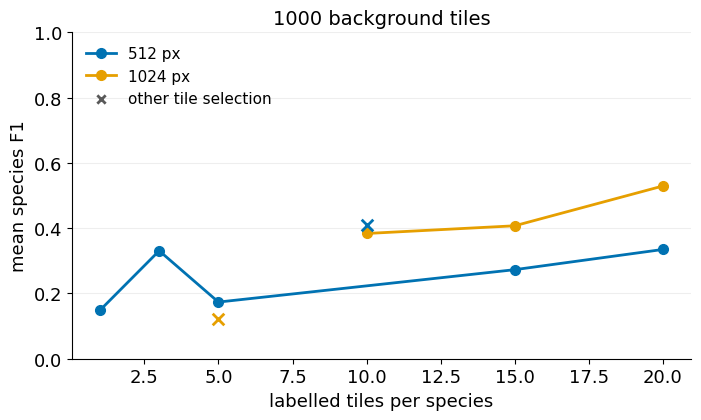

In [10]:
held = scored[scored["bg"] == 1000]
fig, ax = plt.subplots(figsize=(7.2, 4.4))
draw_series(ax, held, "k", "f1_species")
finish_score_axis(ax, "labelled tiles per species")
ax.set_ylabel("mean species F1")
ax.legend(frameon=False, loc="upper left")
ax.set_title("1000 background tiles")
fig.tight_layout()
save(fig, "tiles_per_species_bg1000.png")


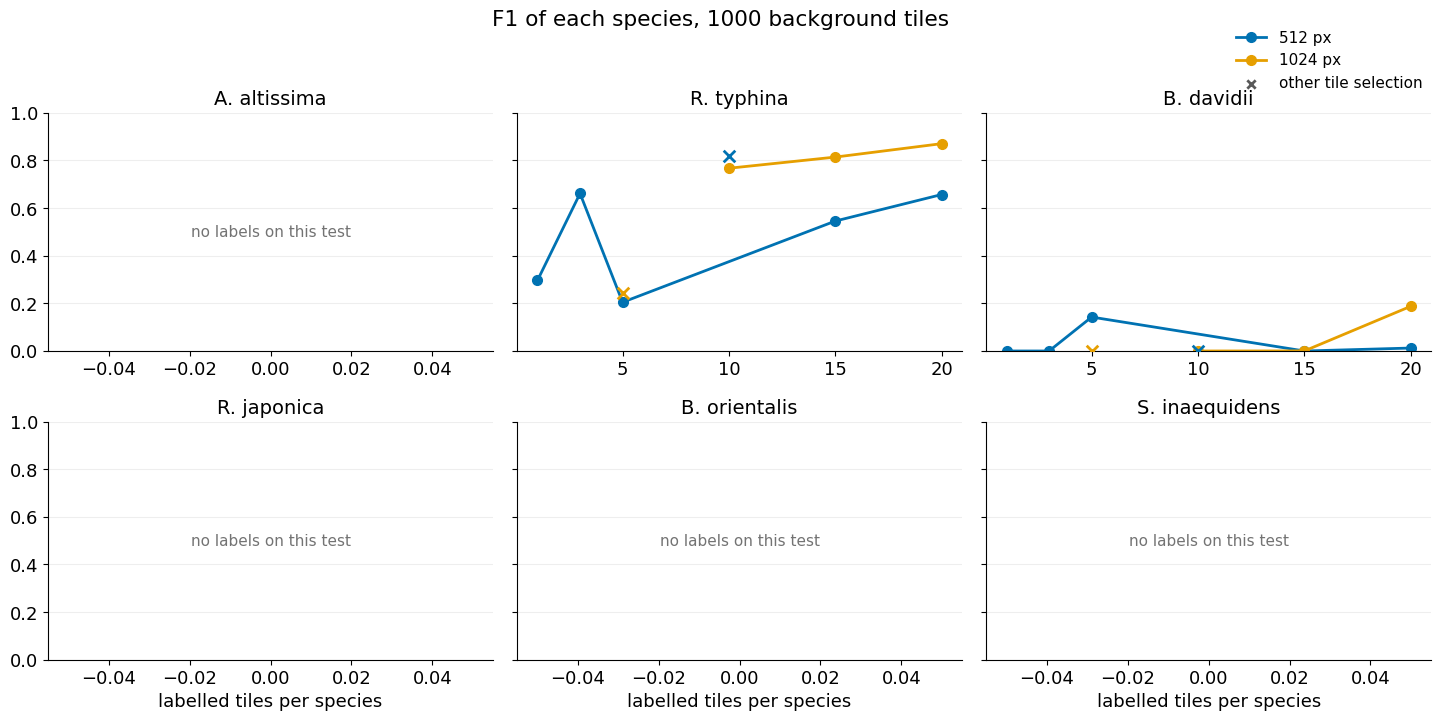

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(14.6, 7.0), sharey=True)
for index, (ax, species) in enumerate(zip(axes.ravel(), SPECIES)):
    draw_series(ax, held, "k", species)
    finish_score_axis(ax, "labelled tiles per species" if index >= 3 else "")
    ax.set_title(species)
    blank_if_unlabelled(ax, held, species)
legend_once(fig, axes)
fig.suptitle("F1 of each species, 1000 background tiles", y=1.03)
fig.tight_layout()
save(fig, "species_f1_vs_tiles_bg1000.png")


## Background tiles

`k = 10` and `k = 15` are the two settings that were repeated across several background counts. The x-axis is logarithmic. The first figure is mean species F1. The grid is each species, with a dashed line for `k = 10` and a solid line for `k = 15`. Same mark rule as above: the cross at 1000 background tiles for `k = 10` is the 512 px run that did not use `max_px_site_pheno`.


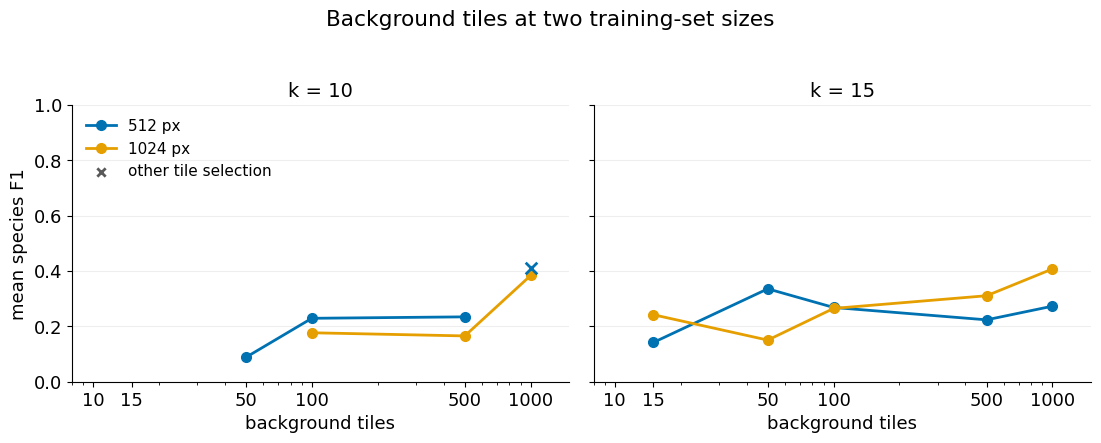

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.3), sharey=True)
for ax, k in zip(axes, (10, 15)):
    draw_series(ax, scored[scored["k"] == k], "bg", "f1_species")
    finish_score_axis(ax, "background tiles")
    style_log_bg(ax)
    ax.set_title(f"k = {k}")
    ax.set_ylabel("mean species F1")
axes[1].set_ylabel("")
axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("Background tiles at two training-set sizes", y=1.03)
fig.tight_layout()
save(fig, "background_tiles.png")



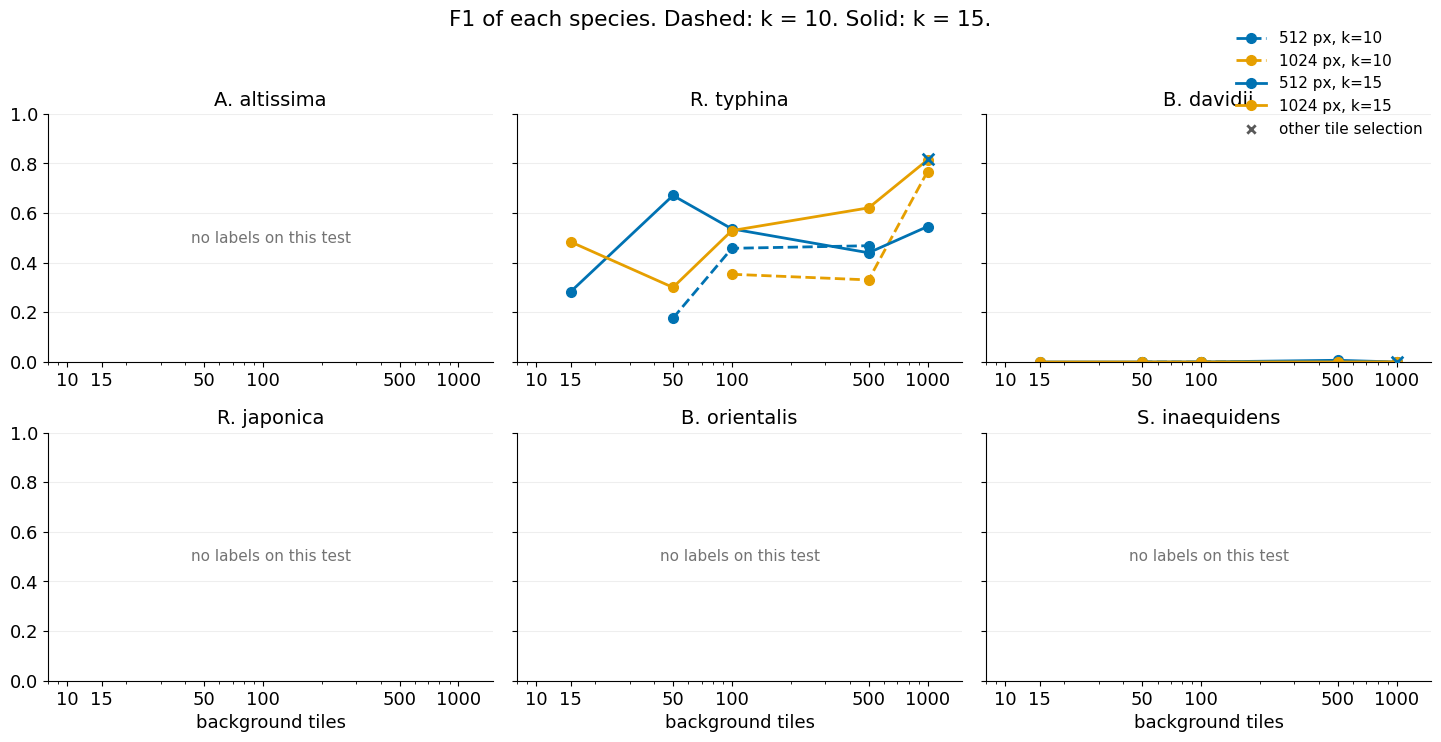

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(14.6, 7.2), sharey=True)
for index, (ax, species) in enumerate(zip(axes.ravel(), SPECIES)):
    for k, linestyle in ((10, "--"), (15, "-")):
        draw_series(
            ax, scored[scored["k"] == k], "bg", species,
            linestyle=linestyle, label_suffix=f", k={k}",
        )
    finish_score_axis(ax, "background tiles" if index >= 3 else "")
    style_log_bg(ax)
    ax.set_title(species)
    blank_if_unlabelled(ax, scored[scored["k"].isin([10, 15])], species)
legend_once(fig, axes)
fig.suptitle("F1 of each species. Dashed: k = 10. Solid: k = 15.", y=1.03)
fig.tight_layout()
save(fig, "species_f1_vs_background.png")


## Crop size, at the same tile counts

Each point is a `(k, background)` pair that was trained at both 512 px and 1024 px. The score is mean species F1. Above the diagonal, the 1024 px crop scored higher. Hatched bars, and open circles, are pairs whose two runs did not both use `max_px_site_pheno`.

The heatmaps show every tested run, including pairs that exist at only one crop size. An empty cell was not trained. A star is a run whose selection mode is not `max_px_site_pheno`.


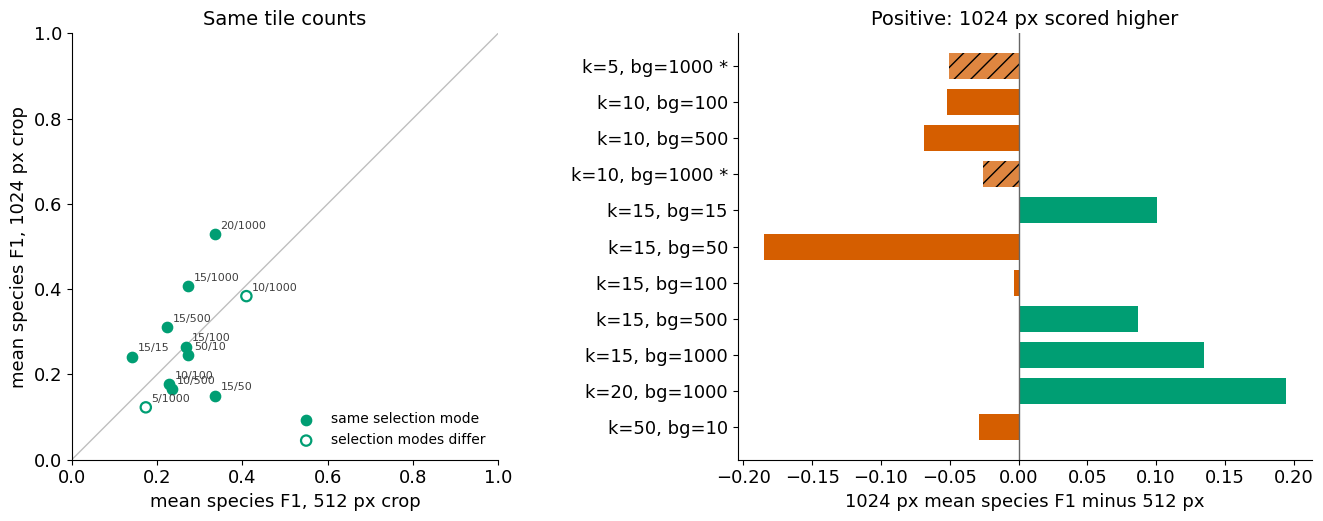

,k,bg,f1_512,f1_1024,delta,mode_512,mode_1024
0,5,1000,0.173594,0.122853,-0.050740,max_px_site_pheno,max_px_pheno
1,10,100,0.229061,0.176790,-0.052271,max_px_site_pheno,max_px_site_pheno
2,10,500,0.234292,0.165413,-0.068880,max_px_site_pheno,max_px_site_pheno
3,10,1000,0.409487,0.383683,-0.025803,max_px,max_px_site_pheno
4,15,15,0.141663,0.242002,0.100339,max_px_site_pheno,max_px_site_pheno
5,15,50,0.335501,0.150301,-0.185200,max_px_site_pheno,max_px_site_pheno
6,15,100,0.268204,0.264755,-0.003450,max_px_site_pheno,max_px_site_pheno
7,15,500,0.223504,0.310555,0.087051,max_px_site_pheno,max_px_site_pheno
8,15,1000,0.272836,0.407295,0.134460,max_px_site_pheno,max_px_site_pheno
9,20,1000,0.334747,0.529196,0.194448,max_px_site_pheno,max_px_site_pheno


In [14]:
wide_512 = scored[scored["crop"] == 512].set_index(["k", "bg"])
wide_1024 = scored[scored["crop"] == 1024].set_index(["k", "bg"])
pairs = []
for key in wide_512.index.intersection(wide_1024.index):
    left = wide_512.loc[key]
    right = wide_1024.loc[key]
    pairs.append({
        "k": int(key[0]),
        "bg": int(key[1]),
        "f1_512": float(left["f1_species"]),
        "f1_1024": float(right["f1_species"]),
        "both_standard": bool(left["standard_mode"] and right["standard_mode"]),
        "mode_512": left["mode"],
        "mode_1024": right["mode"],
    })
paired = pd.DataFrame(pairs).sort_values(["k", "bg"]).reset_index(drop=True)
paired["delta"] = paired["f1_1024"] - paired["f1_512"]
paired["label"] = paired.apply(
    lambda row: f"k={row.k}, bg={row.bg}" + ("" if row.both_standard else " *"),
    axis=1,
)

fig, axes = plt.subplots(1, 2, figsize=(13.8, 5.4))

standard = paired[paired["both_standard"]]
mixed = paired[~paired["both_standard"]]
axes[0].plot([0, 1], [0, 1], color="0.75", lw=1, zorder=0)
axes[0].scatter(
    standard["f1_512"], standard["f1_1024"],
    s=55, color="#009E73", zorder=2, label="same selection mode",
)
axes[0].scatter(
    mixed["f1_512"], mixed["f1_1024"],
    s=55, facecolors="none", edgecolors="#009E73", linewidths=1.6,
    zorder=2, label="selection modes differ",
)
for row in paired.itertuples(index=False):
    axes[0].annotate(
        f"{row.k}/{row.bg}", (row.f1_512, row.f1_1024),
        textcoords="offset points", xytext=(4, 4), fontsize=8, color="0.25",
    )
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)
axes[0].set_xlabel("mean species F1, 512 px crop")
axes[0].set_ylabel("mean species F1, 1024 px crop")
axes[0].set_title("Same tile counts")
axes[0].legend(frameon=False, loc="lower right", fontsize=10)
axes[0].set_aspect("equal", adjustable="box")

colors = ["#009E73" if delta >= 0 else "#D55E00" for delta in paired["delta"]]
bars = axes[1].barh(paired["label"], paired["delta"], color=colors, height=0.72)
for bar, is_standard in zip(bars, paired["both_standard"]):
    if not is_standard:
        bar.set_hatch("//")
        bar.set_alpha(0.75)
axes[1].axvline(0, color="0.4", lw=1)
axes[1].set_xlabel("1024 px mean species F1 minus 512 px")
axes[1].set_title("Positive: 1024 px scored higher")
axes[1].invert_yaxis()
fig.tight_layout()
save(fig, "crop_size_matched.png")
paired[["k", "bg", "f1_512", "f1_1024", "delta", "mode_512", "mode_1024"]]


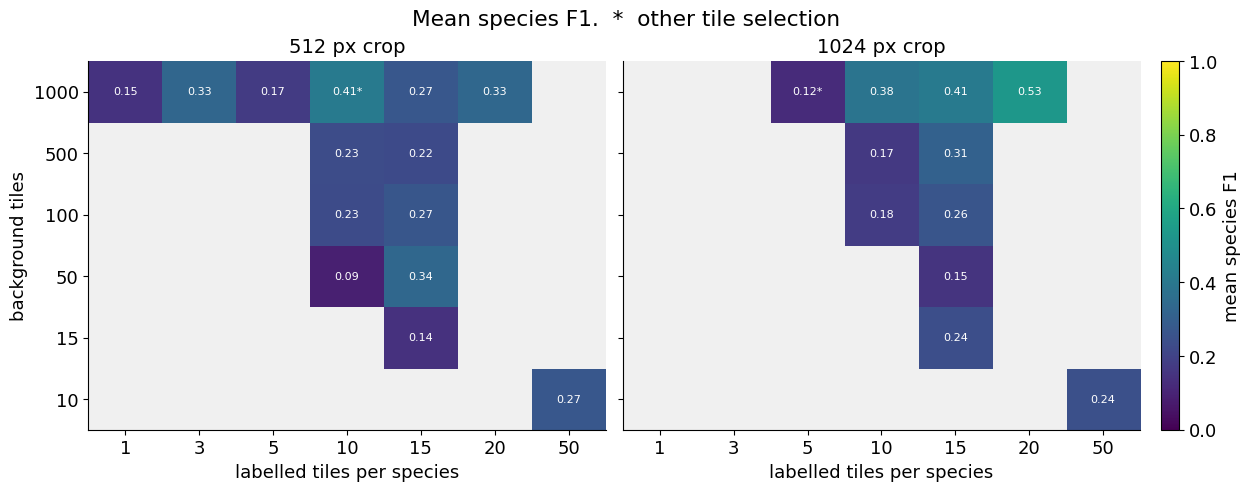

In [15]:
ks = sorted(scored["k"].unique())
bgs = sorted(scored["bg"].unique())
cmap = plt.cm.viridis.copy()
cmap.set_bad("#f0f0f0")

fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.8), sharey=True, layout="constrained")
image = None
for ax, crop in zip(axes, (512, 1024)):
    grid = np.full((len(bgs), len(ks)), np.nan)
    marks = np.full((len(bgs), len(ks)), "", dtype=object)
    part = scored[scored["crop"] == crop]
    for row in part.itertuples(index=False):
        i = bgs.index(row.bg)
        j = ks.index(row.k)
        grid[i, j] = row.f1_species
        marks[i, j] = "" if row.standard_mode else "*"
    image = ax.imshow(
        grid, vmin=0, vmax=1, cmap=cmap, aspect="auto", origin="lower",
    )
    ax.set_xticks(range(len(ks)), [str(k) for k in ks])
    ax.set_yticks(range(len(bgs)), [str(bg) for bg in bgs])
    ax.set_xlabel("labelled tiles per species")
    ax.set_title(f"{crop} px crop")
    for i in range(len(bgs)):
        for j in range(len(ks)):
            value = grid[i, j]
            if np.isnan(value):
                continue
            ax.text(
                j, i, f"{value:.2f}{marks[i, j]}",
                ha="center", va="center", fontsize=8,
                color="white" if value < 0.62 else "black",
            )
axes[0].set_ylabel("background tiles")
fig.colorbar(image, ax=axes, fraction=0.03, pad=0.02, label="mean species F1")
fig.suptitle("Mean species F1.  *  other tile selection")
save(fig, "f1_heatmap.png")
